In [1]:
import pandas as pd
from db_queries import get_location_metadata
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from tqdm import tqdm
import numpy as np
from matplotlib.ticker import MaxNLocator
from pathlib import Path
import yaml
import xarray as xr

# Set paths ####################################################################
RAW_DATA_PATH = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/training_data/2026_09_13.01/data.parquet"
GBD_FILE = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/input/gbd_prevalence/gbd_mean_neonatal_mortality_prevalence.parquet"
INFERENCE_FILE_09_14 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/results/2026_09_14.01/ssp245.parquet"  # Consumption merged on birth year
RESULTS_09_14 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/models/2026_09_14.02/"  # .01 is the input spec; .02 is the fit

# RESULTS_09_21 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/models/2026_09_21.02/"
# RESULTS_09_22 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/models/2026_09_22.02/"
# RESULTS_09_23 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/models/2026_09_23.02/"  # birth_year dropped, consumption_median_RT rescaled to $/day
# RESULTS_09_24 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/models/2026_09_23.03/"  # birth_year dropped, consumption_median_RT, climate variables included
RESULTS_09_25 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/models/2026_09_25.01/"  # final specification, sex_id modified
RESULTS_09_28 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/models/2026_09_25.01/"  # final specification, sex_id modified


# INFERENCE_FILE_09_21 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/results/2026_09_22.01/ssp245.parquet"  # Inclusion of consumption_pd_national_median (logged)
# INFERENCE_FILE_09_22 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/results/2026_09_22.02/ssp245.parquet"  # Inclusion of consumption_pd_national_median (logged)
# INFERENCE_FILE_09_23 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/results/2026_09_23.01/ssp245.parquet"  # model 2026_09_23.02: consumption_median_RT (LDI based), no birth_year
# INFERENCE_FILE_09_24 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/results/2026_09_23.02/ssp245.parquet"  # model 2026_09_24: birth_year dropped, consumption_median_RT, climate variables included
INFERENCE_FILE_09_25 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/results/2026_09_25.02/ssp245.parquet"  # final specification, sex_id modified
INFERENCE_FILE_09_28 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/results/2026_09_28.01/ssp245.parquet"  # final specification, sex_id modified

PLOT_OUTPUT = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/plots/"


df_raw = pd.read_parquet(RAW_DATA_PATH)

# Add location names
locs = get_location_metadata(location_set_id=39, release_id=16)

df_raw = df_raw.merge(
    locs[["location_id", "location_name", "level", "super_region_name"]],
    on="location_id",
    how="left",
)

df_raw.head()

,year_start,year_end,nid,survey_name,int_year,int_month,sex_id,mothers_age_year,aod_months,age_month,...,year_id,age_group_id,int_birth_year_diff_months,log_consumption_pd,sdi,consumption_pd_national_median,consumption_median_RT,location_name,level,super_region_name
0,2009,2010,13109,DHS_MIS,None,None,2,None,0,0,...,2009,42,0,-0.245692,0.318291,2.179549,2.361256,Uganda,3,Sub-Saharan Africa
1,2022,2022,538795,None,2022,5,2,18,0,0,...,2021,42,11,1.312609,0.447416,3.220460,3.404259,United Republic of Tanzania,3,Sub-Saharan Africa
2,2017,2017,353526,None,2017,4,1,20,0,0,...,2017,42,0,2.448691,0.373539,3.087602,4.210878,Senegal,3,Sub-Saharan Africa
3,2019,2021,467681,DHS,None,None,1,None,0,0,...,2020,42,2,1.619791,0.583046,4.671741,5.111802,India,3,South Asia
4,2000,2000,19156,None,2000,2,2,24,0,0,...,1999,42,2,-0.227447,0.340183,1.772798,2.106530,Cambodia,3,"Southeast Asia, East Asia, and Oceania"


60 countries have a fitted random intercept in 2026_09_25.01
survey points: 49 country-years with >= 100 births (Angola, Namibia, Rwanda)
Saved /mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/plots/predictions_09_29_four_countries.pdf


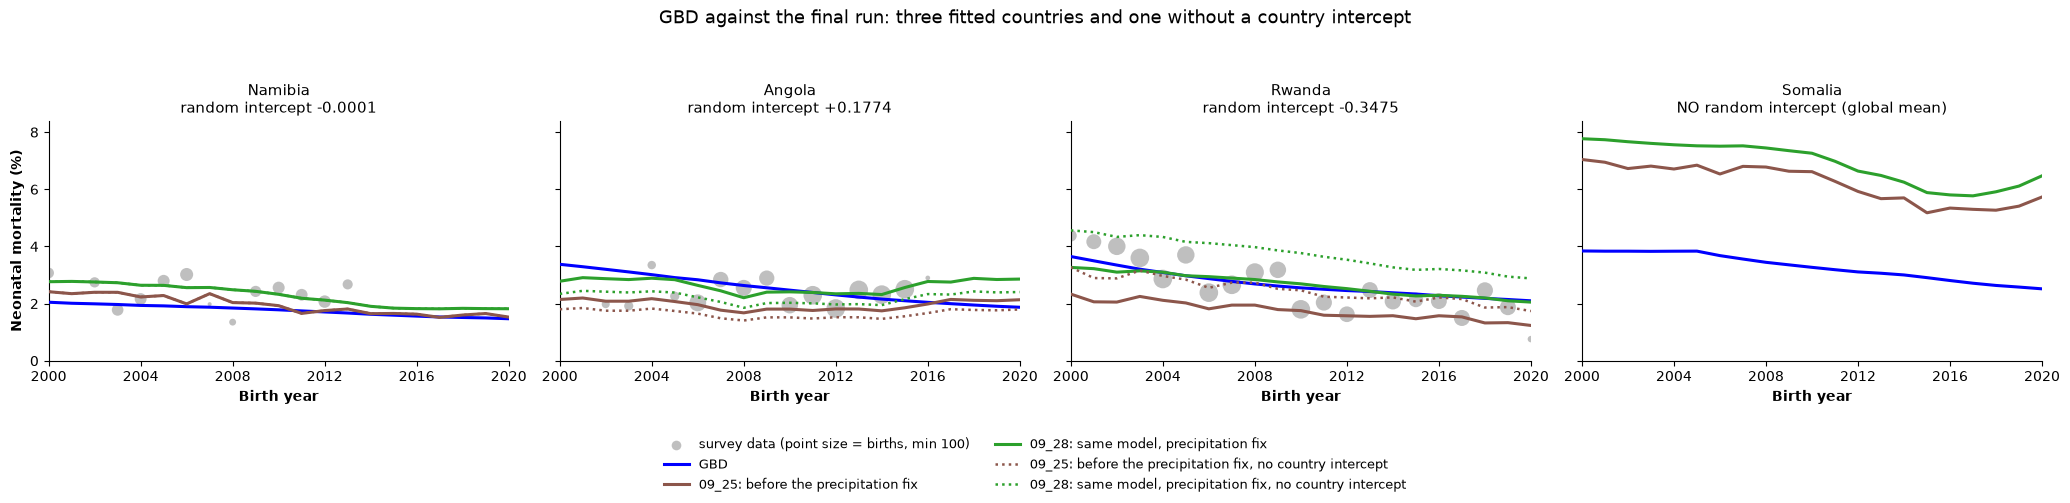


2000 -> 2020 (%):
               gbd_first  gbd_last  i0925_first  i0925_last  i0928_first  i0928_last  i0925_no_re_first  i0925_no_re_last  i0928_no_re_first  i0928_no_re_last
location_name                                                                                                                                                 
Namibia             2.05      1.47         2.42        1.53         2.77        1.82               2.42              1.53               2.77              1.82
Angola              3.38      1.87         2.14        2.14         2.78        2.86               1.80              1.79               2.34              2.41
Rwanda              3.65      2.10         2.33        1.24         3.27        2.05               3.27              1.74               4.56              2.88
Somalia             3.84      2.52         7.04        5.73         7.77        6.47               7.04              5.73               7.77              6.47


In [2]:
# GBD against the final run, three focus countries plus one without a ranef ##
# Same shape as predictions_four_runs_three_countries, cut down to two series:
# GBD and the 2026_09_25.01 fit. Both are sex-averaged, and the inference run
# is averaged over draws.
#
# The fourth panel is the point of the figure. Somalia is Sub-Saharan African
# and appears in the results, but it has no DHS survey in the training data, so
# the model never fitted it a country intercept. Its prediction is the global
# fixed intercept plus covariates, while the other three carry their own
# offset. Each panel says which it is, read from the fit rather than hardcoded.
from scipy.special import expit, logit

R5_COUNTRIES = ["Namibia", "Angola", "Rwanda", "Somalia"]
R5_YEARS = (2000, 2020)
R5_SERIES = {
    "gbd": (GBD_FILE, False, "blue", "GBD"),
    "i0925": (
        INFERENCE_FILE_09_25,
        True,
        "#8c564b",
        "09_25: before the precipitation fix",
    ),
    "i0928": (
        INFERENCE_FILE_09_28,
        True,
        "#2ca02c",
        "09_28: same model, precipitation fix",
    ),
}
R5_RANEF = Path(RESULTS_09_25) / "base_model_ranef.parquet"


def _r5_mean_draw(frame):
    """Inference files carry either draw columns or a long `draw` column."""
    draw_cols = [c for c in frame.columns if c.startswith("draw_")]
    if draw_cols:
        out = frame[[c for c in frame.columns if "draw_" not in c]].copy()
        out["prevalence"] = frame[draw_cols].mean(axis=1)
        return out
    value_col = "value" if "value" in frame.columns else "prevalence"
    keys = [c for c in ("location_id", "year_id", "sex_id") if c in frame.columns]
    return (
        frame.groupby(keys, as_index=False)[value_col]
        .mean()
        .rename(columns={value_col: "prevalence"})
    )


_r5_key = ["location_id", "year_id", "sex_id"]
r5 = None
for col, (path, is_draws, _c, _l) in R5_SERIES.items():
    f = pd.read_parquet(path).reset_index()
    f = (
        _r5_mean_draw(f).rename(columns={"prevalence": col})
        if is_draws
        else f.rename(columns={"gbd_mean_prevalence": col})
    )
    keys = [k for k in _r5_key if k in f.columns]
    f = f[keys + [col]]
    r5 = f if r5 is None else r5.merge(f, on=keys, how="inner")

r5 = (
    r5.merge(
        locs[["location_id", "location_name", "ihme_loc_id"]].drop_duplicates(
            "location_id"
        ),
        on="location_id",
        how="inner",
    )
    .query("year_id >= @R5_YEARS[0] and year_id <= @R5_YEARS[1]")
    .groupby(["location_name", "ihme_loc_id", "year_id"], as_index=False)[
        list(R5_SERIES)
    ]
    .mean()
    .sort_values("year_id")
)

# Which of these countries the model actually fitted an intercept for.
_ranef = pd.read_parquet(R5_RANEF)["offset"]
print(
    f"{_ranef.shape[0]} countries have a fitted random intercept in "
    f"{Path(RESULTS_09_25).name}"
)

# The same prediction with the country intercept taken back out. The published
# value is a mean of expit() over ten income deciles, so subtracting the offset
# from a single aggregate logit is an approximation rather than a re-run of the
# decile integration. Checked against the exact integration using this model's
# own per-decile spline effects: the two agree to within 0.03% relative for
# these countries, which is far below the effect being drawn.
R5_NO_RE = [c for c in R5_SERIES if c != "gbd"]
# A subnational location has no intercept of its own - it inherits its
# country's, because the raster is burned from the national polygon. The
# ihme_loc_id prefix before "_" is that country ("IND_4841" -> "IND"); a
# level-3 code is already its own country, so this is a no-op for them.
_off = r5["ihme_loc_id"].str.split("_").str[0].map(_ranef).fillna(0.0)
for _c in R5_NO_RE:
    r5[f"{_c}_no_re"] = expit(logit(r5[_c].clip(1e-9, 1 - 1e-9)) - _off)

# Observed survey rates behind the lines: mean neonatal_mortality by country
# and birth year, straight from the training data. Years with very few births
# are dropped rather than drawn small - Namibia has a birth year with n=4 and a
# 25% rate, which is noise but would still set the shared y limit.
R5_MIN_BIRTHS = 100
r5_obs = (
    df_raw[df_raw["location_name"].isin(R5_COUNTRIES)]
    .groupby(["location_name", "birth_year"], observed=True)
    .agg(rate=("neonatal_mortality", "mean"), n=("neonatal_mortality", "size"))
    .reset_index()
    .query(
        "n >= @R5_MIN_BIRTHS and birth_year >= @R5_YEARS[0] "
        "and birth_year <= @R5_YEARS[1]"
    )
)
print(
    f"survey points: {len(r5_obs)} country-years with >= {R5_MIN_BIRTHS} births "
    f"({', '.join(sorted(r5_obs['location_name'].unique()))})"
)

_r5_focus = r5[r5["location_name"].isin(R5_COUNTRIES)]
R5_YMAX = (
    100
    * float(
        max(
            _r5_focus[[*R5_SERIES, *(f"{c}_no_re" for c in R5_NO_RE)]].to_numpy().max(),
            r5_obs["rate"].max(),
        )
    )
    * 1.08
)

fig, axes = plt.subplots(
    ncols=len(R5_COUNTRIES), figsize=(5.2 * len(R5_COUNTRIES), 5.0), sharey=True
)
axes = np.atleast_1d(axes)
handles, labels = [], []
for ax, country in zip(axes, R5_COUNTRIES):
    block = r5[r5["location_name"] == country].sort_values("year_id")
    loc = block["ihme_loc_id"].iloc[0]
    obs = r5_obs[r5_obs["location_name"] == country]
    if len(obs):
        ax.scatter(
            obs["birth_year"],
            100 * obs["rate"],
            s=np.clip(obs["n"] / 12, 8, 180),
            color="0.55",
            alpha=0.55,
            linewidths=0,
            zorder=1,
            label=f"survey data (point size = births, min {R5_MIN_BIRTHS})",
        )
    for col, (_p, _d, colour, label) in R5_SERIES.items():
        ax.plot(
            block["year_id"],
            100 * block[col],
            color=colour,
            lw=2.2,
            zorder=3,
            label=label,
        )
    # Dotted: the same run with this country's intercept removed. Drawn only
    # where there is one to remove, so Somalia's single line is unambiguous.
    if loc in _ranef.index:
        for _c in R5_NO_RE:
            ax.plot(
                block["year_id"],
                100 * block[f"{_c}_no_re"],
                color=R5_SERIES[_c][2],
                lw=1.8,
                ls=":",
                zorder=4,
                label=f"{R5_SERIES[_c][3]}, no country intercept",
            )
    ax.set_xlim(*R5_YEARS)
    ax.set_ylim(0, R5_YMAX)
    ax.xaxis.set_major_locator(MaxNLocator(6, integer=True))
    ax.set_xlabel("Birth year", fontweight="bold")
    note = (
        f"random intercept {_ranef[loc]:+.4f}"
        if loc in _ranef.index
        else "NO random intercept (global mean)"
    )
    ax.set_title(f"{country}\n{note}", fontsize=10.5)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    if not handles:
        handles, labels = ax.get_legend_handles_labels()
axes[0].set_ylabel("Neonatal mortality (%)", fontweight="bold")
fig.legend(handles, labels, loc="lower center", ncol=2, fontsize=9, frameon=False)
fig.suptitle(
    "GBD against the final run: three fitted countries and one without a "
    "country intercept",
    fontsize=13,
)
fig.tight_layout(rect=(0, 0.16, 1, 0.93))
plot_path = f"{PLOT_OUTPUT}predictions_09_29_four_countries.pdf"
fig.savefig(plot_path, bbox_inches="tight")
print(f"Saved {plot_path}")
plt.show()

print(f"\n{R5_YEARS[0]} -> {R5_YEARS[1]} (%):")
_ends = (
    _r5_focus.groupby("location_name")
    .agg(
        **{
            f"{c}_{w}": (c, w)
            for c in [*R5_SERIES, *(f"{c}_no_re" for c in R5_NO_RE)]
            for w in ("first", "last")
        }
    )
    .loc[R5_COUNTRIES]
)
print((100 * _ends).round(2).to_string())

2026_09_28.01: predicted residual = +1.1845 -2.8436 x SDI (pp);  constant shift +0.313 pp
Saved /mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/plots/rwanda_residual_steps_annotated_updated.pdf


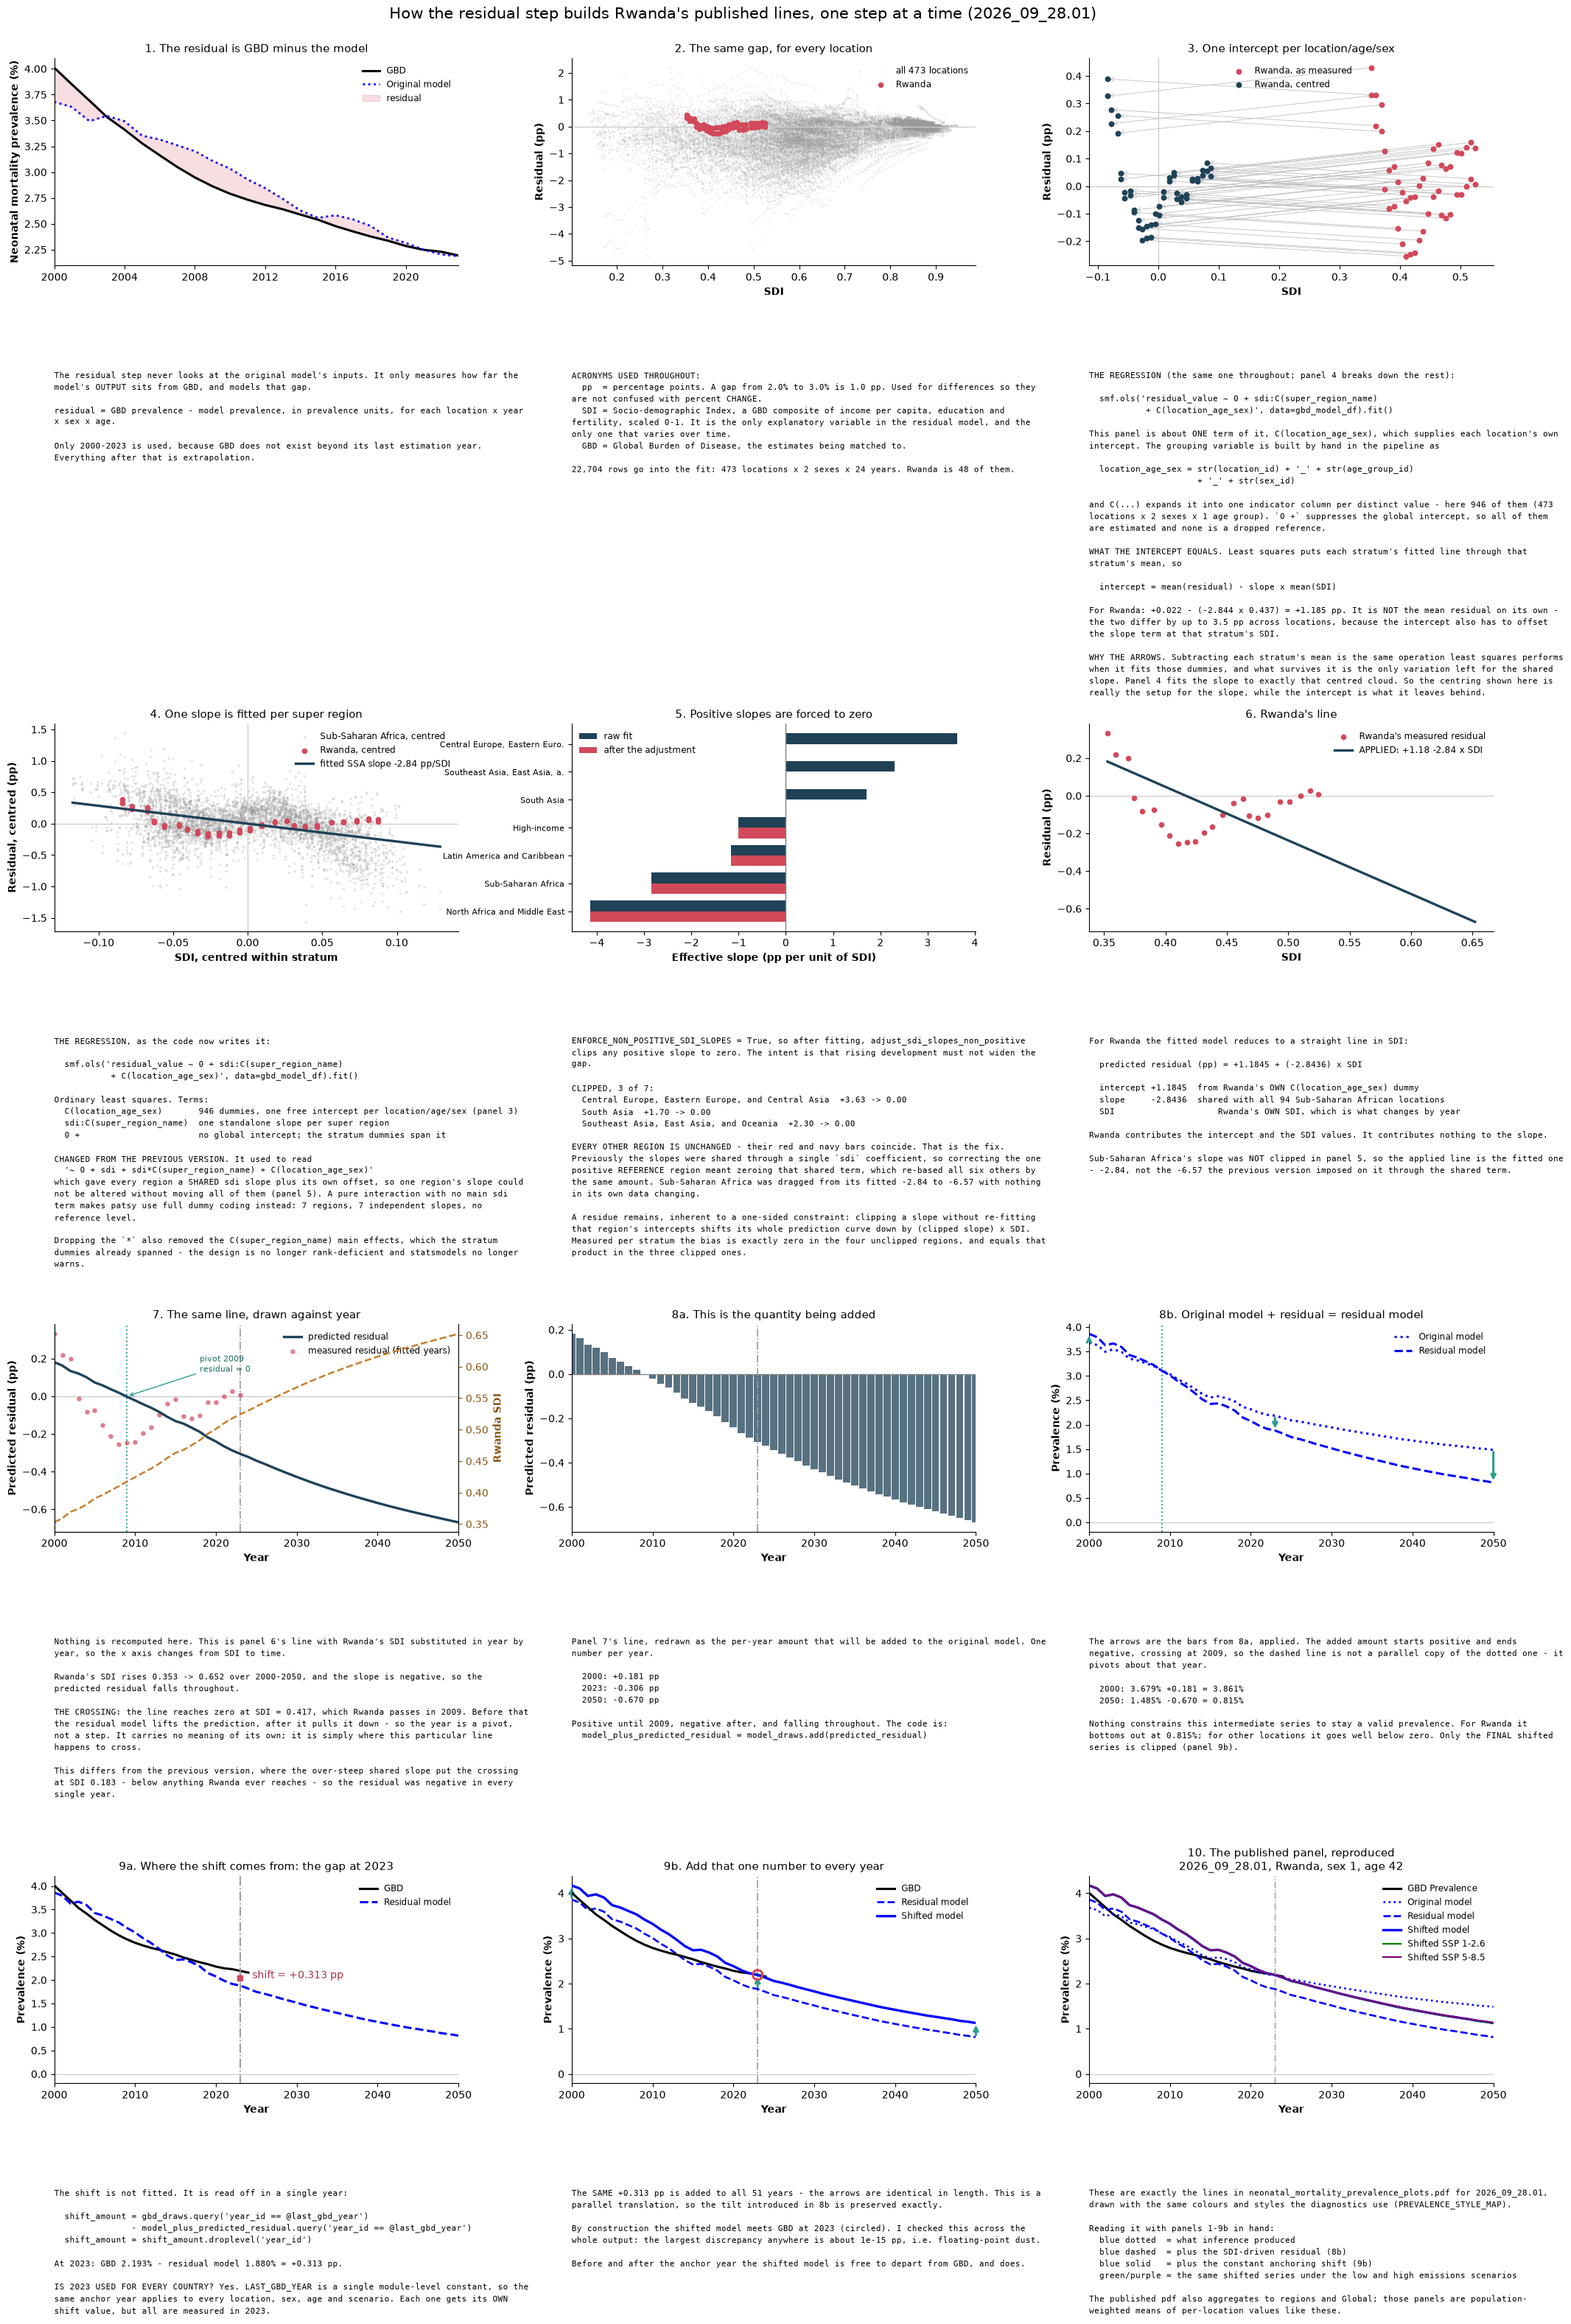

In [3]:
# The residual step for Rwanda, eleven annotated panels #####################
# Self-contained: everything is read from the residual step's own output for
# results 2026_09_28.01 (model 2026_09_25.01, precipitation fix applied), so
# this does not depend on the inference cells above.
import textwrap

import xarray as xr
import re

import statsmodels.formula.api as smf

ST_RV = "2026_09_28.01"
ST_SEV = f"/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/results/{ST_RV}/sev_means.parquet"
ST_PAST_SDI = "/mnt/share/forecasting/data/32/past/sdi/past_sdi_s130v89/sdi.nc"
ST_FUTURE_SDI = "/mnt/share/forecasting/data/32/future/sdi/future_sdi_s130v89/sdi.nc"
ST_SDI_SCENARIO = 130
ST_LOC, ST_SEX, ST_AGE = 185, 1, 42  # Rwanda, male, 0-6 days
ST_LAST_GBD = 2023  # constants.LAST_GBD_YEAR
ST_SR = "Sub-Saharan Africa"
ST_YEARS = (2000, 2050)


def st_load_sdi():
    past = xr.open_dataset(ST_PAST_SDI).to_dataframe().reset_index()
    past = past.groupby(["location_id", "year_id"], as_index=False)["draws"].mean()
    fut = xr.open_dataset(ST_FUTURE_SDI).to_dataframe().reset_index()
    fut = fut[fut["scenario"] == ST_SDI_SCENARIO]
    fut = fut.groupby(["location_id", "year_id"], as_index=False)["draws"].mean()
    return (
        pd.concat([past, fut])
        .rename(columns={"draws": "sdi"})
        .drop_duplicates(["location_id", "year_id"])
    )


st_sdi = st_load_sdi()
st = (
    pd.read_parquet(ST_SEV)
    .reset_index()
    .query("age_group_id == @ST_AGE")
    .merge(st_sdi, on=["location_id", "year_id"], how="left")
    .merge(
        locs[["location_id", "super_region_name", "location_name"]].drop_duplicates(
            "location_id"
        ),
        on="location_id",
        how="left",
    )
)
st["resid"] = 100 * (st["gbd_value"] - st["model_value"])  # observed
st["pred"] = 100 * (st["residual_model_value"] - st["model_value"])  # predicted
st["stratum"] = st.location_id.astype(str) + "_" + st.sex_id.astype(str)

rwa = st.query("location_id == @ST_LOC and sex_id == @ST_SEX").set_index("year_id")
rwa = rwa.sort_index().loc[ST_YEARS[0] : ST_YEARS[1]]
hist = rwa.loc[:ST_LAST_GBD]

# the applied line, recovered exactly (it IS intercept + slope * SDI)
_ok = rwa.dropna(subset=["sdi"])
ST_B, ST_A = np.polyfit(_ok["sdi"], _ok["pred"], 1)

# the raw fit, before the non-positive-slope adjustment
fit_df = (
    st.query("year_id <= @ST_LAST_GBD")
    .dropna(subset=["sdi", "gbd_value", "model_value", "super_region_name"])
    .copy()
)
_m = smf.ols("resid ~ 0 + sdi:C(super_region_name) + C(stratum)", data=fit_df).fit()
# Every level now owns a standalone slope: 'sdi:C(super_region_name)[LEVEL]',
# with no bare 'sdi' term and no reference level.
_pat = re.compile(r"^sdi:C\(super_region_name\)\[(?:T\.)?(.*)\]$")
raw = {
    _pat.match(_t).group(1): float(_m.params[_t])
    for _t in _m.model.exog_names
    if _pat.match(_t)
}
# ENFORCE_NON_POSITIVE_SDI_SLOPES clips a positive slope to zero and leaves
# every other region exactly as fitted.
applied = {_k: min(_v, 0.0) for _k, _v in raw.items()}
ST_CLIPPED = sorted(_k for _k in raw if raw[_k] > 0)

st_ssa = fit_df[fit_df.super_region_name == ST_SR].copy()
for _c in ("resid", "sdi"):
    st_ssa[f"{_c}_w"] = st_ssa[_c] - st_ssa.groupby("stratum")[_c].transform("mean")
_rw_ssa = st_ssa[st_ssa.location_id == ST_LOC]
ZERO_YEAR = int(rwa.index[(rwa["pred"].abs()).argmin()])
SHIFT = 100 * float((rwa["adjusted_model_value"] - rwa["residual_model_value"]).iloc[0])
print(
    f"{ST_RV}: predicted residual = {ST_A:+.4f} {ST_B:+.4f} x SDI (pp);  "
    f"constant shift {SHIFT:+.3f} pp"
)

# ---- the explanations, defined before the figure so the grid can be sized
# to them: a fixed text-row height cannot fit notes that differ by a factor of
# three in length, which is what made them run into the plots below.
NOTES = {}
NOTES[0] = (
    "The residual step never looks at the original model's inputs. It only "
    "measures how far the model's OUTPUT sits from GBD, and models that gap.\n\n"
    "residual = GBD prevalence - model prevalence, in prevalence units, for "
    f"each location x year x sex x age.\n\nOnly {ST_YEARS[0]}-{ST_LAST_GBD} is used, "
    "because GBD does not exist beyond its last estimation year. Everything "
    "after that is extrapolation."
)

NOTES[1] = (
    "ACRONYMS USED THROUGHOUT:\n"
    "  pp  = percentage points. A gap from 2.0% to 3.0% is 1.0 pp. Used for "
    "differences so they are not confused with percent CHANGE.\n"
    "  SDI = Socio-demographic Index, a GBD composite of income per capita, "
    "education and fertility, scaled 0-1. It is the only explanatory variable "
    "in the residual model, and the only one that varies over time.\n"
    "  GBD = Global Burden of Disease, the estimates being matched to.\n\n"
    f"{len(fit_df):,} rows go into the fit: {fit_df.location_id.nunique()} "
    f"locations x 2 sexes x {fit_df.year_id.nunique()} years. Rwanda is "
    f"{len(_rw_ssa)} of them."
)

NOTES[2] = (
    "THE REGRESSION (the same one throughout; panel 4 breaks down the rest):\n\n"
    "  smf.ols('residual_value ~ 0 + sdi:C(super_region_name)\n"
    "           + C(location_age_sex)', data=gbd_model_df).fit()\n\n"
    "This panel is about ONE term of it, C(location_age_sex), which supplies "
    "each location's own intercept. The grouping variable is built by hand in "
    "the pipeline as\n\n"
    "  location_age_sex = str(location_id) + '_' + str(age_group_id)\n"
    "                     + '_' + str(sex_id)\n\n"
    "and C(...) expands it into one indicator column per distinct value - here "
    f"{fit_df.stratum.nunique():,} of them "
    f"({fit_df.location_id.nunique()} locations x 2 sexes x 1 age group). "
    "`0 +` suppresses the global intercept, so all of them are estimated and "
    "none is a dropped reference.\n\n"
    "WHAT THE INTERCEPT EQUALS. Least squares puts each stratum's fitted line "
    "through that stratum's mean, so\n\n"
    "  intercept = mean(residual) - slope x mean(SDI)\n\n"
    f"For Rwanda: {_rw_ssa.resid.mean():+.3f} - ({raw[ST_SR]:+.3f} x "
    f"{_rw_ssa.sdi.mean():.3f}) = {ST_A:+.3f} pp. It is NOT the mean residual "
    "on its own - the two differ by up to 3.5 pp across locations, because the "
    "intercept also has to offset the slope term at that stratum's SDI.\n\n"
    "WHY THE ARROWS. Subtracting each stratum's mean is the same operation "
    "least squares performs when it fits those dummies, and what survives it "
    "is the only variation left for the shared slope. Panel 4 fits the slope "
    "to exactly that centred cloud. So the centring shown here is really the "
    "setup for the slope, while the intercept is what it leaves behind."
)

NOTES[3] = (
    "THE REGRESSION, as the code now writes it:\n\n"
    "  smf.ols('residual_value ~ 0 + sdi:C(super_region_name)\n"
    "           + C(location_age_sex)', data=gbd_model_df).fit()\n\n"
    "Ordinary least squares. Terms:\n"
    f"  C(location_age_sex)       {fit_df.stratum.nunique():,} dummies, one "
    "free intercept per location/age/sex (panel 3)\n"
    "  sdi:C(super_region_name)  one standalone slope per super region\n"
    "  0 +                       no global intercept; the stratum dummies span "
    "it\n\n"
    "CHANGED FROM THE PREVIOUS VERSION. It used to read\n"
    "  '~ 0 + sdi + sdi*C(super_region_name) + C(location_age_sex)'\n"
    "which gave every region a SHARED sdi slope plus its own offset, so one "
    "region's slope could not be altered without moving all of them (panel 5). "
    "A pure interaction with no main sdi term makes patsy use full dummy coding "
    f"instead: {len(raw)} regions, {len(raw)} independent slopes, no reference "
    "level.\n\n"
    "Dropping the `*` also removed the C(super_region_name) main effects, which "
    "the stratum dummies already spanned - the design is no longer "
    "rank-deficient and statsmodels no longer warns."
)

NOTES[4] = (
    "ENFORCE_NON_POSITIVE_SDI_SLOPES = True, so after fitting, "
    "adjust_sdi_slopes_non_positive clips any positive slope to zero. The "
    "intent is that rising development must not widen the gap.\n\n"
    f"CLIPPED, {len(ST_CLIPPED)} of {len(raw)}:\n"
    + "".join(f"  {_k}  {raw[_k]:+.2f} -> 0.00\n" for _k in ST_CLIPPED)
    + "\nEVERY OTHER REGION IS UNCHANGED - their red and navy bars coincide. "
    "That is the fix. Previously the slopes were shared through a single `sdi` "
    "coefficient, so correcting the one positive REFERENCE region meant zeroing "
    "that shared term, which re-based all six others by the same amount. "
    "Sub-Saharan Africa was dragged from its fitted -2.84 to -6.57 with nothing "
    "in its own data changing.\n\n"
    "A residue remains, inherent to a one-sided constraint: clipping a slope "
    "without re-fitting that region's intercepts shifts its whole prediction "
    "curve down by (clipped slope) x SDI. Measured per stratum the bias is "
    "exactly zero in the four unclipped regions, and equals that product in the "
    "three clipped ones."
)

NOTES[5] = (
    "For Rwanda the fitted model reduces to a straight line in SDI:\n\n"
    f"  predicted residual (pp) = {ST_A:+.4f} + ({ST_B:+.4f}) x SDI\n\n"
    f"  intercept {ST_A:+.4f}  from Rwanda's OWN C(location_age_sex) dummy\n"
    f"  slope     {ST_B:+.4f}  shared with all "
    f"{st_ssa.location_id.nunique()} Sub-Saharan African locations\n"
    "  SDI                    Rwanda's OWN SDI, which is what changes by year\n\n"
    "Rwanda contributes the intercept and the SDI values. It contributes "
    "nothing to the slope.\n\n"
    + (
        "Sub-Saharan Africa's slope was NOT clipped in panel 5, so the applied "
        f"line is the fitted one - {ST_B:+.2f}, not the {-6.57:+.2f} the "
        "previous version imposed on it through the shared term."
        if ST_SR not in ST_CLIPPED
        else "Sub-Saharan Africa's slope WAS clipped; the grey dashed line is "
        "where it would sit as fitted."
    )
)

NOTES[6] = (
    "Nothing is recomputed here. This is panel 6's line with Rwanda's SDI "
    "substituted in year by year, so the x axis changes from SDI to time.\n\n"
    f"Rwanda's SDI rises {rwa.sdi.iloc[0]:.3f} -> {rwa.sdi.iloc[-1]:.3f} over "
    f"{ST_YEARS[0]}-{ST_YEARS[1]}, and the slope is negative, so the predicted "
    "residual falls throughout.\n\n"
    f"THE CROSSING: the line reaches zero at SDI = {ST_A / -ST_B:.3f}, which "
    f"Rwanda passes in {ZERO_YEAR}. Before that the residual model lifts the "
    "prediction, after it pulls it down - so the year is a pivot, not a step. "
    "It carries no meaning of its own; it is simply where this particular "
    "line happens to cross.\n\n"
    "This differs from the previous version, where the over-steep shared slope "
    "put the crossing at SDI 0.183 - below anything Rwanda ever reaches - so "
    "the residual was negative in every single year."
)

NOTES[7] = (
    "Panel 7's line, redrawn as the per-year amount that will be added to the "
    "original model. One number per year.\n\n"
    f"  {ST_YEARS[0]}: {rwa.pred.iloc[0]:+.3f} pp\n"
    f"  {ST_LAST_GBD}: {rwa.loc[ST_LAST_GBD, 'pred']:+.3f} pp\n"
    f"  {ST_YEARS[1]}: {rwa.pred.iloc[-1]:+.3f} pp\n\n"
    f"Positive until {ZERO_YEAR}, negative after, and falling throughout. "
    "The code is:\n"
    "  model_plus_predicted_residual = model_draws.add(predicted_residual)"
)

NOTES[8] = (
    "The arrows are the bars from 8a, applied. The added amount starts "
    f"positive and ends negative, crossing at {ZERO_YEAR}, so the dashed line "
    "is not a parallel copy of the dotted one - it pivots about that year.\n\n"
    f"  {ST_YEARS[0]}: {100 * rwa.model_value.iloc[0]:.3f}% "
    f"{rwa.pred.iloc[0]:+.3f} = {100 * rwa.residual_model_value.iloc[0]:.3f}%\n"
    f"  {ST_YEARS[1]}: {100 * rwa.model_value.iloc[-1]:.3f}% "
    f"{rwa.pred.iloc[-1]:+.3f} = "
    f"{100 * rwa.residual_model_value.iloc[-1]:.3f}%\n\n"
    "Nothing constrains this intermediate series to stay a valid prevalence. "
    f"For Rwanda it bottoms out at "
    f"{100 * rwa.residual_model_value.min():.3f}%; for other locations it goes "
    "well below zero. Only the FINAL shifted series is clipped (panel 9b)."
)

NOTES[9] = (
    "The shift is not fitted. It is read off in a single year:\n\n"
    "  shift_amount = gbd_draws.query('year_id == @last_gbd_year')\n"
    "               - model_plus_predicted_residual.query('year_id == "
    "@last_gbd_year')\n"
    "  shift_amount = shift_amount.droplevel('year_id')\n\n"
    f"At {ST_LAST_GBD}: GBD {100 * rwa.loc[ST_LAST_GBD, 'gbd_value']:.3f}% "
    f"- residual model "
    f"{100 * rwa.loc[ST_LAST_GBD, 'residual_model_value']:.3f}% = "
    f"{SHIFT:+.3f} pp.\n\n"
    f"IS {ST_LAST_GBD} USED FOR EVERY COUNTRY? Yes. LAST_GBD_YEAR is a single "
    "module-level constant, so the same anchor year applies to every location, "
    "sex, age and scenario. Each one gets its OWN shift value, but all are "
    f"measured in {ST_LAST_GBD}."
)

NOTES[10] = (
    f"The SAME {SHIFT:+.3f} pp is added to all {len(rwa)} years - the arrows "
    "are identical in length. This is a parallel translation, so the tilt "
    "introduced in 8b is preserved exactly.\n\n"
    f"By construction the shifted model meets GBD at {ST_LAST_GBD} (circled). "
    "I checked this across the whole output: the largest discrepancy anywhere "
    "is about 1e-15 pp, i.e. floating-point dust.\n\n"
    "Before and after the anchor year the shifted model is free to depart from "
    "GBD, and does."
)

NOTES[11] = (
    "These are exactly the lines in neonatal_mortality_prevalence_plots.pdf "
    f"for {ST_RV}, drawn with the same colours and styles the diagnostics use "
    "(PREVALENCE_STYLE_MAP).\n\n"
    "Reading it with panels 1-9b in hand:\n"
    "  blue dotted  = what inference produced\n"
    "  blue dashed  = plus the SDI-driven residual (8b)\n"
    "  blue solid   = plus the constant anchoring shift (9b)\n"
    "  green/purple = the same shifted series under the low and high emissions "
    "scenarios\n\n"
    "The published pdf also aggregates to regions and Global; those panels are "
    "population-weighted means of per-location values like these."
)

ST_WRAP = 92
ST_NOTE_FS = 8.2
ST_LINE_IN = 0.165  # height of one wrapped line at that font size
ST_NOTE_PAD = 0.45  # breathing room above and below each note
ST_PLOT_IN = 4.2  # height of every plot row
ST_COL_IN = 7.0  # width of every column

st_wrapped = {}
for _i in range(12):
    st_wrapped[_i] = "\n".join(
        textwrap.fill(_p, ST_WRAP, replace_whitespace=False) if _p.strip() else ""
        for _p in NOTES.get(_i, "").split("\n")
    )
# each text row is as tall as the longest note sitting in it
_row_lines = [
    max(st_wrapped[_r * 3 + _c].count("\n") + 1 for _c in range(3)) for _r in range(4)
]
_text_in = [n * ST_LINE_IN + ST_NOTE_PAD for n in _row_lines]
_heights = []
for _r in range(4):
    _heights += [ST_PLOT_IN, _text_in[_r]]
ST_FIG_H = sum(_heights) + 1.2

fig, axg = plt.subplots(
    8,
    3,
    figsize=(ST_COL_IN * 3, ST_FIG_H),
    gridspec_kw={"height_ratios": _heights, "hspace": 0.55, "wspace": 0.28},
)
P = [axg[2 * (i // 3), i % 3] for i in range(12)]
T = [axg[2 * (i // 3) + 1, i % 3] for i in range(12)]

# 1 --------------------------------------------------------------------------
P[0].plot(hist.index, 100 * hist.gbd_value, color="black", lw=2.2, label="GBD")
P[0].plot(
    hist.index,
    100 * hist.model_value,
    color="blue",
    ls=":",
    lw=2.0,
    label="Original model",
)
P[0].fill_between(
    hist.index,
    100 * hist.model_value,
    100 * hist.gbd_value,
    color="#d1495b",
    alpha=0.18,
    label="residual",
)
P[0].set_title("1. The residual is GBD minus the model", fontsize=11)
P[0].set_ylabel("Neonatal mortality prevalence (%)", fontweight="bold")

# 2 --------------------------------------------------------------------------
P[1].scatter(
    fit_df.sdi,
    fit_df.resid,
    s=4,
    color="0.6",
    alpha=0.15,
    linewidths=0,
    label=f"all {fit_df.location_id.nunique()} locations",
)
P[1].scatter(
    _rw_ssa.sdi,
    _rw_ssa.resid,
    s=30,
    color="#d1495b",
    linewidths=0,
    zorder=4,
    label="Rwanda",
)
P[1].axhline(0, color="0.8", lw=0.9)
P[1].set_title("2. The same gap, for every location", fontsize=11)
P[1].set_xlabel("SDI", fontweight="bold")
P[1].set_ylabel("Residual (pp)", fontweight="bold")

# 3 --------------------------------------------------------------------------
P[2].scatter(
    _rw_ssa.sdi,
    _rw_ssa.resid,
    s=32,
    color="#d1495b",
    linewidths=0,
    zorder=4,
    label="Rwanda, as measured",
)
P[2].scatter(
    _rw_ssa.sdi_w,
    _rw_ssa.resid_w,
    s=32,
    color="#1f4257",
    linewidths=0,
    zorder=4,
    label="Rwanda, centred",
)
for _x, _y, _xw, _yw in zip(_rw_ssa.sdi, _rw_ssa.resid, _rw_ssa.sdi_w, _rw_ssa.resid_w):
    P[2].annotate(
        "",
        xy=(_xw, _yw),
        xytext=(_x, _y),
        arrowprops=dict(arrowstyle="->", color="0.75", lw=0.6),
    )
P[2].axhline(0, color="0.8", lw=0.9)
P[2].axvline(0, color="0.8", lw=0.9)
P[2].set_title("3. One intercept per location/age/sex", fontsize=11)
P[2].set_xlabel("SDI", fontweight="bold")
P[2].set_ylabel("Residual (pp)", fontweight="bold")

# 4 --------------------------------------------------------------------------
P[3].scatter(
    st_ssa.sdi_w,
    st_ssa.resid_w,
    s=6,
    color="0.6",
    alpha=0.25,
    linewidths=0,
    label="Sub-Saharan Africa, centred",
)
P[3].scatter(
    _rw_ssa.sdi_w,
    _rw_ssa.resid_w,
    s=30,
    color="#d1495b",
    linewidths=0,
    zorder=4,
    label="Rwanda, centred",
)
_xw = np.linspace(st_ssa.sdi_w.min(), st_ssa.sdi_w.max(), 50)
P[3].plot(
    _xw,
    raw[ST_SR] * _xw,
    color="#1f4257",
    lw=2.4,
    zorder=5,
    label=f"fitted SSA slope {raw[ST_SR]:+.2f} pp/SDI",
)
P[3].axhline(0, color="0.8", lw=0.9)
P[3].axvline(0, color="0.8", lw=0.9)
P[3].set_title("4. One slope is fitted per super region", fontsize=11)
P[3].set_xlabel("SDI, centred within stratum", fontweight="bold")
P[3].set_ylabel("Residual, centred (pp)", fontweight="bold")

# 5 --------------------------------------------------------------------------
_names = sorted(raw, key=lambda k: raw[k])
_y = np.arange(len(_names))
_h = 0.38
P[4].barh(_y + _h / 2, [raw[n] for n in _names], _h, color="#1f4257", label="raw fit")
P[4].barh(
    _y - _h / 2,
    [applied[n] for n in _names],
    _h,
    color="#d1495b",
    label="after the adjustment",
)
P[4].axvline(0, color="0.5", lw=1.0)
P[4].set_yticks(_y, [n if len(n) < 30 else n[:28] + "." for n in _names], fontsize=8)
P[4].set_title("5. Positive slopes are forced to zero", fontsize=11)
P[4].set_xlabel("Effective slope (pp per unit of SDI)", fontweight="bold")

# 6 --------------------------------------------------------------------------
_xs = np.linspace(rwa.sdi.min(), rwa.sdi.max(), 50)
P[5].scatter(
    hist.sdi,
    hist.resid,
    s=30,
    color="#d1495b",
    linewidths=0,
    zorder=4,
    label="Rwanda's measured residual",
)
if ST_SR in ST_CLIPPED:
    P[5].plot(
        _xs,
        _rw_ssa.resid.mean() + raw[ST_SR] * (_xs - _rw_ssa.sdi.mean()),
        color="0.55",
        lw=1.8,
        ls="--",
        zorder=4,
        label=f"as fitted, before clipping {raw[ST_SR]:+.2f}",
    )
P[5].plot(
    _xs,
    ST_A + ST_B * _xs,
    color="#1f4257",
    lw=2.4,
    zorder=5,
    label=f"APPLIED: {ST_A:+.2f} {ST_B:+.2f} x SDI",
)
P[5].axhline(0, color="0.8", lw=0.9)
P[5].set_title("6. Rwanda's line", fontsize=11)
P[5].set_xlabel("SDI", fontweight="bold")
P[5].set_ylabel("Residual (pp)", fontweight="bold")

# 7 --------------------------------------------------------------------------
P[6].plot(
    rwa.index, rwa.pred, color="#1f4257", lw=2.4, zorder=4, label="predicted residual"
)
P[6].scatter(
    hist.index,
    hist.resid,
    s=22,
    color="#d1495b",
    alpha=0.7,
    linewidths=0,
    zorder=3,
    label="measured residual (fitted years)",
)
P[6].axhline(0, color="0.8", lw=1.0)
P[6].axvline(ST_LAST_GBD, color="0.6", lw=1.2, ls="-.", zorder=2)
P[6].axvline(ZERO_YEAR, color="#2a9d8f", lw=1.4, ls=":", zorder=2)
P[6].annotate(
    f"pivot {ZERO_YEAR}\nresidual = 0",
    xy=(ZERO_YEAR, 0),
    xytext=(ZERO_YEAR + 9, 0.72 * rwa.pred.max()),
    fontsize=8,
    color="#1f6f68",
    arrowprops=dict(arrowstyle="->", color="#2a9d8f", lw=1),
)
_a7 = P[6].twinx()
_a7.plot(rwa.index, rwa.sdi, color="#c77f2a", lw=1.8, ls="--")
_a7.set_ylabel("Rwanda SDI", color="#8a5616", fontweight="bold")
_a7.tick_params(axis="y", colors="#8a5616")
_a7.spines["top"].set_visible(False)
P[6].set_title("7. The same line, drawn against year", fontsize=11)
P[6].set_xlabel("Year", fontweight="bold")
P[6].set_ylabel("Predicted residual (pp)", fontweight="bold")

# 8a -------------------------------------------------------------------------
P[7].bar(rwa.index, rwa.pred, color="#1f4257", alpha=0.75, width=0.9)
P[7].axhline(0, color="0.5", lw=1.0)
P[7].axvline(ST_LAST_GBD, color="0.6", lw=1.2, ls="-.")
P[7].set_title("8a. This is the quantity being added", fontsize=11)
P[7].set_xlabel("Year", fontweight="bold")
P[7].set_ylabel("Predicted residual (pp)", fontweight="bold")

# 8b -------------------------------------------------------------------------
P[8].plot(
    rwa.index,
    100 * rwa.model_value,
    color="blue",
    ls=":",
    lw=2.2,
    label="Original model",
    zorder=3,
)
P[8].plot(
    rwa.index,
    100 * rwa.residual_model_value,
    color="blue",
    ls="--",
    lw=2.2,
    label="Residual model",
    zorder=4,
)
for _y0 in (ST_YEARS[0], ST_LAST_GBD, ST_YEARS[1]):
    P[8].annotate(
        "",
        xy=(_y0, 100 * rwa.loc[_y0, "residual_model_value"]),
        xytext=(_y0, 100 * rwa.loc[_y0, "model_value"]),
        arrowprops=dict(arrowstyle="->", color="#2a9d8f", lw=2.2),
    )
P[8].axvline(ZERO_YEAR, color="#2a9d8f", lw=1.4, ls=":", zorder=2)
P[8].axhline(0, color="0.8", lw=0.9)
P[8].set_title("8b. Original model + residual = residual model", fontsize=11)
P[8].set_xlabel("Year", fontweight="bold")
P[8].set_ylabel("Prevalence (%)", fontweight="bold")

# 9a -------------------------------------------------------------------------
P[9].plot(rwa.index, 100 * rwa.gbd_value, color="black", lw=2.2, label="GBD")
P[9].plot(
    rwa.index,
    100 * rwa.residual_model_value,
    color="blue",
    ls="--",
    lw=2.2,
    label="Residual model",
)
P[9].axvline(ST_LAST_GBD, color="0.6", lw=1.4, ls="-.")
P[9].annotate(
    "",
    xy=(ST_LAST_GBD, 100 * rwa.loc[ST_LAST_GBD, "gbd_value"]),
    xytext=(ST_LAST_GBD, 100 * rwa.loc[ST_LAST_GBD, "residual_model_value"]),
    arrowprops=dict(arrowstyle="<->", color="#d1495b", lw=2.6),
)
P[9].text(
    ST_LAST_GBD + 1.5,
    0.5
    * (
        100 * rwa.loc[ST_LAST_GBD, "gbd_value"]
        + 100 * rwa.loc[ST_LAST_GBD, "residual_model_value"]
    ),
    f"shift = {SHIFT:+.3f} pp",
    fontsize=10,
    color="#a1303f",
)
P[9].axhline(0, color="0.8", lw=0.9)
P[9].set_title(f"9a. Where the shift comes from: the gap at {ST_LAST_GBD}", fontsize=11)
P[9].set_xlabel("Year", fontweight="bold")
P[9].set_ylabel("Prevalence (%)", fontweight="bold")

# 9b -------------------------------------------------------------------------
P[10].plot(rwa.index, 100 * rwa.gbd_value, color="black", lw=2.2, label="GBD", zorder=5)
P[10].plot(
    rwa.index,
    100 * rwa.residual_model_value,
    color="blue",
    ls="--",
    lw=1.9,
    label="Residual model",
    zorder=4,
)
P[10].plot(
    rwa.index,
    100 * rwa.adjusted_model_value,
    color="blue",
    lw=2.4,
    label="Shifted model",
    zorder=5,
)
for _y0 in (ST_YEARS[0], ST_LAST_GBD, ST_YEARS[1]):
    P[10].annotate(
        "",
        xy=(_y0, 100 * rwa.loc[_y0, "adjusted_model_value"]),
        xytext=(_y0, 100 * rwa.loc[_y0, "residual_model_value"]),
        arrowprops=dict(arrowstyle="->", color="#2a9d8f", lw=2.2),
    )
P[10].scatter(
    [ST_LAST_GBD],
    [100 * rwa.loc[ST_LAST_GBD, "gbd_value"]],
    s=90,
    facecolor="none",
    edgecolor="#d1495b",
    lw=2.2,
    zorder=6,
)
P[10].axvline(ST_LAST_GBD, color="0.6", lw=1.2, ls="-.")
P[10].axhline(0, color="0.8", lw=0.9)
P[10].set_title("9b. Add that one number to every year", fontsize=11)
P[10].set_xlabel("Year", fontweight="bold")
P[10].set_ylabel("Prevalence (%)", fontweight="bold")

# 10 -------------------------------------------------------------------------
_FINAL = [
    ("gbd_value", "black", "-", 2.2, "GBD Prevalence"),
    ("model_value", "blue", ":", 1.9, "Original model"),
    ("residual_model_value", "blue", "--", 1.9, "Residual model"),
    ("adjusted_model_value", "blue", "-", 2.4, "Shifted model"),
    ("adjusted_ssp126", "green", "-", 1.6, "Shifted SSP 1-2.6"),
    ("adjusted_ssp585", "purple", "-", 1.6, "Shifted SSP 5-8.5"),
]
for _c, _col, _ls, _lw, _lab in _FINAL:
    if _c in rwa.columns:
        P[11].plot(rwa.index, 100 * rwa[_c], color=_col, ls=_ls, lw=_lw, label=_lab)
P[11].axvline(ST_LAST_GBD, color="0.6", lw=1.0, ls="-.")
P[11].axhline(0, color="0.8", lw=0.9)
P[11].set_title(
    f"10. The published panel, reproduced\n{ST_RV}, Rwanda, sex {ST_SEX}, "
    f"age {ST_AGE}",
    fontsize=11,
)
P[11].set_xlabel("Year", fontweight="bold")
P[11].set_ylabel("Prevalence (%)", fontweight="bold")

ST_YEAR_PANELS = {0, 6, 7, 8, 9, 10, 11}
for _i, _ax in enumerate(P):
    if _i in ST_YEAR_PANELS:
        _ax.set_xlim(ST_YEARS[0], ST_LAST_GBD if _i == 0 else ST_YEARS[1])
        _ax.xaxis.set_major_locator(MaxNLocator(6, integer=True))
    _ax.set_axisbelow(True)
    for _s in ("top", "right"):
        _ax.spines[_s].set_visible(False)
    if _ax.get_legend_handles_labels()[0]:
        _ax.legend(fontsize=8.5, frameon=False)

for _i, _ax in enumerate(T):
    _ax.axis("off")
    _ax.text(
        0,
        1,
        st_wrapped[_i],
        va="top",
        ha="left",
        fontsize=ST_NOTE_FS,
        family="monospace",
        linespacing=1.4,
        transform=_ax.transAxes,
    )

fig.suptitle(
    "How the residual step builds Rwanda's published lines, one step at a time "
    f"({ST_RV})",
    fontsize=15,
    y=1 - 0.35 / ST_FIG_H,
)
fig.subplots_adjust(left=0.055, right=0.985, top=1 - 1.05 / ST_FIG_H, bottom=0.012)
plot_path = f"{PLOT_OUTPUT}rwanda_residual_steps_annotated_updated.pdf"
fig.savefig(plot_path, bbox_inches="tight", pad_inches=0.3)
print(f"Saved {plot_path}")
plt.show()

In [13]:
# Two subsets of the residual step's prevalence plots ########################
# Reproduces what make_results_plots does, in this kernel, so it needs no
# rra_climate_health import:
#   1. read sev_means.parquet, clip the shifted columns to [0, 1] as the
#      diagnostics do
#   2. population-weight the most-detailed locations up the FHS hierarchy
#   3. draw one page per location, same line styles as the published pdf
# Then write two pdfs: Global + the 7 super regions, and the level-3 countries.
SUB_RV = "2026_09_28.01"
SUB_MEASURE = "neonatal_mortality"
SUB_ROOT = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition"
SUB_SEV = f"{SUB_ROOT}/{SUB_MEASURE}/results/{SUB_RV}/sev_means.parquet"
SUB_HIER = f"{SUB_ROOT}/input/fhs_hierarchy.parquet"
SUB_POP_FUT = "/mnt/share/forecasting/data/32/future/population/future_population_s130v41/population.nc"
SUB_POP_PAST = "/mnt/share/forecasting/data/16/past/population/20250603_etl_run_id_417/population.nc"
SUB_POP_SCENARIO = 130
SUB_REFERENCE = "ssp245"
SUB_ANCHOR = 2023  # constants.LAST_GBD_YEAR, where the shift is read off

# line styles copied from residual_diagnostics.PREVALENCE_STYLE_MAP / LABEL_MAP
SUB_STYLE = [
    ("gbd_value", "black", "-", "GBD Prevalence"),
    ("adjusted_constant_climate", "lightgreen", "-", "Shifted constant climate"),
    ("adjusted_ssp585", "purple", "-", "Shifted SSP 5-8.5"),
    ("adjusted_ssp126", "green", "-", "Shifted SSP 1-2.6"),
    ("model_value", "blue", ":", "Original model"),
    ("residual_model_value", "blue", "--", "Residual model"),
    ("adjusted_model_value", "blue", "-", "Shifted model"),
]

sub_res = pd.read_parquet(SUB_SEV)
sub_hier = pd.read_parquet(SUB_HIER)
_ages = sorted(sub_res.index.get_level_values("age_group_id").unique())
_sexes = sorted(sub_res.index.get_level_values("sex_id").unique())
_years = sorted(sub_res.index.get_level_values("year_id").unique())

# the clipping make_results_plots applies before aggregating
for _c in [c for c in sub_res.columns if c.startswith("adjusted_")]:
    sub_res[_c] = sub_res[_c].clip(0, 1)


# Reported age groups that the population files store only as their parts,
# mirroring constants.AGE_GROUP_AGGREGATES. Neonatal's 42 is early + late
# neonatal, so the population has to be summed over [2, 3] first.
SUB_AGE_AGGREGATES = {
    4: [388, 389],
    5: [238, 34],
    42: [2, 3],
    1: [2, 3, 388, 389, 238, 34],
}


def sub_load_population():
    """Past + future population means, on the sev_means demographic grid."""
    detailed = sorted({a for age in _ages for a in SUB_AGE_AGGREGATES.get(age, [age])})
    fut = (
        xr.open_dataset(SUB_POP_FUT)
        .sel(age_group_id=detailed, sex_id=_sexes, scenario=SUB_POP_SCENARIO)
        .to_dataframe()
        .reset_index()
    )
    past = (
        xr.open_dataset(SUB_POP_PAST)
        .sel(age_group_id=detailed, sex_id=_sexes)
        .to_dataframe()
        .reset_index()
    )
    out = []
    for df in (past, fut):
        val = "population" if "population" in df.columns else "draws"
        keys = ["location_id", "year_id", "age_group_id", "sex_id"]
        df = (
            df.groupby(keys, as_index=False)[val]
            .mean()
            .rename(columns={val: "population"})
        )
        # roll the detailed groups back up into the reported ones
        parts = []
        for age in _ages:
            members = SUB_AGE_AGGREGATES.get(age, [age])
            sub = df[df.age_group_id.isin(members)].copy()
            sub["age_group_id"] = age
            parts.append(sub.groupby(keys, as_index=False)["population"].sum())
        out.append(pd.concat(parts))
    pop = pd.concat(out)
    # past and future overlap; the forecast file wins, matching the pipeline
    pop = pop.drop_duplicates(
        ["location_id", "year_id", "age_group_id", "sex_id"], keep="last"
    )
    return pop[pop.year_id.isin(_years)]


sub_pop = sub_load_population()

# FHS forecast q0s, for reference against the pipeline's own lines. These files
# already carry every level of the hierarchy - Global, super regions, regions,
# countries and subnationals - at age_group_id 42, so they merge straight on
# without any aggregation of their own. Values are plain probabilities
# (rate_denominator = 1), the same scale as gbd_value, so they only need x100.
SUB_FHS = {
    "fhs_with_cuts": (
        "/mnt/share/forecasting/data/32/future/death/"
        "20260717_q0_reference_s130v108_noreagg_nq0",
        "#d1495b",
        "-",
        "FHS forecasts with ODA cuts",
    ),
    "fhs_no_cuts": (
        "/mnt/share/forecasting/data/32/future/death/"
        "20260716_q0_reference_s130v98_nq0",
        "#d1495b",
        "--",
        "FHS forecasts without ODA cuts",
    ),
}


def sub_load_fhs():
    """Draw-averaged day28q0 for both ODA scenarios, keyed like sub_agg."""
    out = None
    for col, (path, *_rest) in SUB_FHS.items():
        da = xr.open_dataarray(f"{path}/day28q0.nc")
        df = (
            da.sel(scenario=130, sex_id=_sexes)
            .mean(dim="draw")
            .squeeze()
            .to_dataframe()
            .reset_index()
            .rename(columns={"value": col})
        )
        keys = ["location_id", "year_id", "sex_id", "age_group_id"]
        df = df[keys + [col]]
        out = df if out is None else out.merge(df, on=keys, how="outer")
    return out


sub_fhs = sub_load_fhs()
print(
    f"FHS overlay: {sub_fhs.location_id.nunique()} locations, "
    f"{int(sub_fhs.year_id.min())}-{int(sub_fhs.year_id.max())}, "
    f"age {sorted(sub_fhs.age_group_id.unique())}"
)

# population-weight every most-detailed location up its path_to_top_parent
_detailed = sub_hier[sub_hier["most_detailed"] == 1][
    ["location_id", "path_to_top_parent"]
]
_vals = [c for c, *_ in SUB_STYLE if c in sub_res.columns]
_flat = (
    sub_res.reset_index()
    .merge(_detailed, on="location_id", how="inner")
    .merge(
        sub_pop, on=["location_id", "year_id", "age_group_id", "sex_id"], how="inner"
    )
)
_flat["agg_id"] = _flat["path_to_top_parent"].str.split(",")
_exp = _flat.explode("agg_id")
_exp["agg_id"] = _exp["agg_id"].astype(int)
for _c in _vals:
    _exp[_c] = _exp[_c] * _exp["population"]
_keys = ["agg_id", "year_id", "age_group_id", "sex_id"]
sub_agg = _exp.groupby(_keys, as_index=False)[_vals + ["population"]].sum(min_count=1)
for _c in _vals:
    sub_agg[_c] = sub_agg[_c] / sub_agg["population"]
sub_agg = sub_agg.rename(columns={"agg_id": "location_id"})

# Raw survey data, to overlay on the country pages. It is coded to country
# level and by BIRTH year, plotted against the model's year axis; sex_id is a
# string in the training extract so it needs coercing to match.
SUB_MIN_BIRTHS = 100
sub_obs = (
    df_raw.assign(sex_id=lambda d: pd.to_numeric(d["sex_id"], errors="coerce"))
    .dropna(subset=["sex_id", "birth_year", "neonatal_mortality"])
    .groupby(["location_id", "birth_year", "sex_id"], observed=True)
    .agg(rate=("neonatal_mortality", "mean"), n=("neonatal_mortality", "size"))
    .reset_index()
    .query("n >= @SUB_MIN_BIRTHS")
)
sub_obs["sex_id"] = sub_obs["sex_id"].astype(int)
print(
    f"survey overlay: {len(sub_obs):,} country/year/sex cells with "
    f">= {SUB_MIN_BIRTHS} births, {sub_obs.location_id.nunique()} countries"
)

_lv = sub_hier.set_index("location_id")["level"]
_nm = sub_hier.set_index("location_id")["location_name"]
print(
    f"aggregated to {sub_agg.location_id.nunique()} locations "
    f"from {_flat.location_id.nunique()} most-detailed inputs; "
    f"levels {sorted(set(_lv.reindex(sub_agg.location_id.unique()).dropna().astype(int)))}"
)


def sub_make_pdf(loc_ids, out_path, title_note, *, overlay_survey=False):
    """One page per location: a sex-by-age grid, styled like the published pdf."""
    with PdfPages(out_path) as pdf:
        for loc_id in loc_ids:
            fig, axes = plt.subplots(
                len(_sexes),
                len(_ages),
                figsize=(14, 8),
                sharex=True,
                sharey=True,
                squeeze=False,
            )
            handles, labels = [], []
            for j, sex_id in enumerate(_sexes):
                for i, age_id in enumerate(_ages):
                    ax = axes[j, i]
                    blk = sub_agg[
                        (sub_agg.location_id == loc_id)
                        & (sub_agg.sex_id == sex_id)
                        & (sub_agg.age_group_id == age_id)
                    ].sort_values("year_id")
                    if overlay_survey:
                        # behind the lines; point size scales with births so
                        # thin survey years read as less reliable
                        o = sub_obs[
                            (sub_obs.location_id == loc_id) & (sub_obs.sex_id == sex_id)
                        ]
                        if len(o):
                            ax.scatter(
                                o.birth_year,
                                o.rate,
                                s=np.clip(o.n / 60, 4, 60),
                                color="0.45",
                                alpha=0.55,
                                linewidths=0,
                                zorder=0,
                                label=f"survey data (size = births, "
                                f"min {SUB_MIN_BIRTHS})",
                            )
                    for col, colour, ls, lab in SUB_STYLE:
                        if col in blk.columns:
                            ax.plot(
                                blk.year_id, blk[col], color=colour, ls=ls, label=lab
                            )
                    # FHS reference forecasts; 2024-2050 only, so these appear
                    # as a segment rather than spanning the panel
                    f = sub_fhs[
                        (sub_fhs.location_id == loc_id)
                        & (sub_fhs.sex_id == sex_id)
                        & (sub_fhs.age_group_id == age_id)
                    ].sort_values("year_id")
                    for col, (_pth, colour, ls, lab) in SUB_FHS.items():
                        if col in f.columns and f[col].notna().any():
                            ax.plot(
                                f.year_id,
                                f[col],
                                color=colour,
                                ls=ls,
                                lw=1.8,
                                zorder=5,
                                label=lab,
                            )
                    # the anchor year: the shifted model meets GBD here by
                    # construction, and GBD itself stops here
                    ax.axvline(
                        SUB_ANCHOR,
                        color="0.45",
                        lw=1.1,
                        ls="-.",
                        zorder=1,
                        label=f"anchor year {SUB_ANCHOR}",
                    )
                    ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.5)
                    if j == 0:
                        ax.set_title(f"Age group {age_id}")
                    ax.set_ylabel("Male" if sex_id == 1 else "Female")
                    if i > 0:
                        ax.set_ylabel("")
                        ax.tick_params(labelleft=False)
                    if j == len(_sexes) - 1:
                        ax.set_xlabel("Year")
                    if not handles:
                        handles, labels = ax.get_legend_handles_labels()
            fig.suptitle(
                f"{SUB_MEASURE.capitalize()} Prevalence - Location {loc_id}: "
                f"{_nm.get(loc_id)}",
                fontsize=16,
            )
            fig.legend(
                handles, labels, loc="lower center", ncol=3, bbox_to_anchor=(0.5, 0)
            )
            fig.tight_layout(rect=[0, 0.05, 1, 1])
            pdf.savefig(fig)
            plt.close(fig)
    print(f"Saved {out_path} ({len(loc_ids)} pages, {title_note})")


_ordered = [l for l in sub_agg.location_id.unique() if l in _lv.index]
# The survey data is coded to country level, so it goes on the country pages
# only; putting a national rate on a super-region panel would mix grains.
SUB_SETS = {
    "global_superregions": (
        [l for l in _ordered if _lv[l] in (0, 1)],
        "Global and the super regions",
        False,
    ),
    "countries": ([l for l in _ordered if _lv[l] == 3], "level-3 countries", True),
}
for _tag, (_locs, _note, _ov) in SUB_SETS.items():
    sub_make_pdf(
        _locs,
        f"{PLOT_OUTPUT}{SUB_MEASURE}_prevalence_plots_{_tag}.pdf",
        _note,
        overlay_survey=_ov,
    )

FHS overlay: 538 locations, 2024-2050, age [42]
survey overlay: 1,681 country/year/sex cells with >= 100 births, 60 countries
aggregated to 513 locations from 473 most-detailed inputs; levels [0, 1, 2, 3, 4]
Saved /mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/plots/neonatal_mortality_prevalence_plots_global_superregions.pdf (8 pages, Global and the super regions)
Saved /mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/plots/neonatal_mortality_prevalence_plots_countries.pdf (204 pages, level-3 countries)


In [5]:
# Residual model: per-location parameter estimates ##########################
# The pipeline prints residual_model_sr.summary() to the task log and saves
# nothing, so there is no record of what the model actually estimated for each
# place. This refits the same regression here and writes the per-location
# estimates out as a csv.
#
# Refitting rather than reading coefficients back off the predictions, because
# only a fit gives standard errors. The point estimates are cross-checked
# against the saved predicted residual at the end - they must agree exactly,
# since predicted_residual IS intercept + slope x SDI.
import re

import statsmodels.formula.api as smf

EST_OUT = f"{PLOT_OUTPUT}residual_model_location_estimates.csv"
EST_PAST_SDI = "/mnt/share/forecasting/data/32/past/sdi/past_sdi_s130v89/sdi.nc"
EST_FUTURE_SDI = "/mnt/share/forecasting/data/32/future/sdi/future_sdi_s130v89/sdi.nc"
EST_SDI_SCENARIO = 130


def est_load_sdi():
    """Draw-averaged past + future SDI, as residual_data.get_sdi builds it."""
    past = xr.open_dataset(EST_PAST_SDI).to_dataframe().reset_index()
    past = past.groupby(["location_id", "year_id"], as_index=False)["draws"].mean()
    fut = xr.open_dataset(EST_FUTURE_SDI).to_dataframe().reset_index()
    fut = fut[fut["scenario"] == EST_SDI_SCENARIO]
    fut = fut.groupby(["location_id", "year_id"], as_index=False)["draws"].mean()
    return (
        pd.concat([past, fut])
        .rename(columns={"draws": "sdi"})
        .drop_duplicates(["location_id", "year_id"])
    )


est_sdi = est_load_sdi()

est_src = (
    pd.read_parquet(SUB_SEV)
    .reset_index()
    .merge(
        sub_pop[["location_id", "year_id", "age_group_id", "sex_id"]].drop_duplicates(),
        on=["location_id", "year_id", "age_group_id", "sex_id"],
        how="left",
    )
    .merge(
        sub_hier[
            [
                "location_id",
                "location_name",
                "level",
                "super_region_name",
                "region_name",
            ]
        ],
        on="location_id",
        how="left",
    )
    .merge(est_sdi, on=["location_id", "year_id"], how="left")
)
est_src["obs"] = 100 * (est_src.gbd_value - est_src.model_value)
est_src["pred"] = 100 * (est_src.residual_model_value - est_src.model_value)
est_src["las"] = (
    est_src.location_id.astype(str)
    + "_"
    + est_src.age_group_id.astype(str)
    + "_"
    + est_src.sex_id.astype(str)
)
est_fit = (
    est_src.query("year_id <= @SUB_ANCHOR")
    .dropna(subset=["obs", "sdi", "super_region_name"])
    .copy()
)

# the same formula the pipeline now uses
est_model = smf.ols("obs ~ 0 + sdi:C(super_region_name) + C(las)", data=est_fit).fit()
_sl = re.compile(r"^sdi:C\(super_region_name\)\[(?:T\.)?(.*)\]$")
_ic = re.compile(r"^C\(las\)\[(?:T\.)?(.*)\]$")
slope = {
    _sl.match(t).group(1): (est_model.params[t], est_model.bse[t])
    for t in est_model.model.exog_names
    if _sl.match(t)
}
icept = {
    _ic.match(t).group(1): (est_model.params[t], est_model.bse[t])
    for t in est_model.model.exog_names
    if _ic.match(t)
}
print(
    f"refit: {len(est_fit):,} rows, {len(icept):,} location/age/sex intercepts, "
    f"{len(slope)} super-region slopes, R2 {est_model.rsquared:.4f}"
)

# ENFORCE_NON_POSITIVE_SDI_SLOPES: positives clipped, others left as fitted
est_rows = []
for las, g in est_fit.groupby("las"):
    sr = g.super_region_name.iloc[0]
    b_raw, b_se = slope[sr]
    a, a_se = icept.get(las, (np.nan, np.nan))
    b_app = min(b_raw, 0.0)
    obs_mean = g.obs.mean()
    est_rows.append(
        {
            "location_id": int(g.location_id.iloc[0]),
            "location_name": g.location_name.iloc[0],
            "level": int(g.level.iloc[0]),
            "super_region_name": sr,
            "region_name": g.region_name.iloc[0],
            "age_group_id": int(g.age_group_id.iloc[0]),
            "sex_id": int(g.sex_id.iloc[0]),
            "n_years_fitted": int(g.year_id.nunique()),
            "mean_sdi_fitted": g.sdi.mean(),
            "intercept_pp": a,
            "intercept_se_pp": a_se,
            "sdi_slope_raw_pp_per_sdi": b_raw,
            "sdi_slope_se_pp_per_sdi": b_se,
            "sdi_slope_applied_pp_per_sdi": b_app,
            "slope_was_clipped": b_raw > 0,
            "mean_observed_residual_pp": obs_mean,
        }
    )
est = pd.DataFrame(est_rows)

# what the pipeline actually produced, for comparison and for the shift
_p = []
for _las, _g in est_src.dropna(subset=["sdi"]).groupby("las"):
    _b, _a = np.polyfit(_g.sdi, _g.pred, 1)
    _p.append({"las": _las, "pred_intercept_pp": _a, "pred_slope_pp_per_sdi": _b})
_p = pd.DataFrame(_p)
_shift = est_src[est_src.year_id == SUB_ANCHOR].assign(
    shift_pp=lambda d: 100 * (d.adjusted_model_value - d.residual_model_value)
)[["las", "shift_pp"]]
est["las"] = (
    est.location_id.astype(str)
    + "_"
    + est.age_group_id.astype(str)
    + "_"
    + est.sex_id.astype(str)
)
est = est.merge(_p, on="las", how="left").merge(
    _shift.rename(columns={"shift_pp": "anchor_shift_pp"}), on="las", how="left"
)
est["mean_predicted_residual_pp"] = (
    est.pred_intercept_pp + est.pred_slope_pp_per_sdi * est.mean_sdi_fitted
)
est["bias_pp"] = est.mean_predicted_residual_pp - est.mean_observed_residual_pp

_d_a = (est.intercept_pp - est.pred_intercept_pp).abs().max()
_d_b = (est.sdi_slope_applied_pp_per_sdi - est.pred_slope_pp_per_sdi).abs().max()
print(
    f"  cross-check against the saved predictions: max |intercept diff| "
    f"{_d_a:.2e} pp, max |slope diff| {_d_b:.2e} pp/SDI"
)

est = est.drop(columns=["las"]).sort_values(
    ["super_region_name", "location_name", "sex_id"]
)
est.to_csv(EST_OUT, index=False)
print(f"Saved {EST_OUT}  ({len(est):,} rows, one per location/age/sex)")
print(
    f"  clipped slopes affect {est.slope_was_clipped.sum():,} of {len(est):,} rows "
    f"in {est.loc[est.slope_was_clipped, 'super_region_name'].nunique()} super regions"
)
print("\nby super region (sex 1), mean across locations:")
_s = (
    est[est.sex_id == 1]
    .groupby("super_region_name")
    .agg(
        n=("location_id", "nunique"),
        slope_raw=("sdi_slope_raw_pp_per_sdi", "first"),
        slope_applied=("sdi_slope_applied_pp_per_sdi", "first"),
        intercept=("intercept_pp", "mean"),
        obs=("mean_observed_residual_pp", "mean"),
        pred=("mean_predicted_residual_pp", "mean"),
        bias=("bias_pp", "mean"),
        shift=("anchor_shift_pp", "mean"),
    )
    .round(3)
)
print(_s.to_string())
est.head(12)

refit: 22,704 rows, 946 location/age/sex intercepts, 7 super-region slopes, R2 0.9062
  cross-check against the saved predictions: max |intercept diff| 6.06e-07 pp, max |slope diff| 8.42e-07 pp/SDI
Saved /mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/plots/residual_model_location_estimates.csv  (946 rows, one per location/age/sex)
  clipped slopes affect 338 of 946 rows in 3 super regions

by super region (sex 1), mean across locations:
                                                   n  slope_raw  slope_applied  intercept    obs   pred   bias  shift
super_region_name                                                                                                    
Central Europe, Eastern Europe, and Central Asia  29      3.634          0.000     -3.036 -0.380 -3.036 -2.656  2.761
High-income                                       99     -0.998         -0.998      0.873  0.019  0.019  0.000  0.002
Latin America and Caribbean                   

,location_id,location_name,level,super_region_name,region_name,age_group_id,sex_id,n_years_fitted,mean_sdi_fitted,intercept_pp,...,sdi_slope_raw_pp_per_sdi,sdi_slope_se_pp_per_sdi,sdi_slope_applied_pp_per_sdi,slope_was_clipped,mean_observed_residual_pp,pred_intercept_pp,pred_slope_pp_per_sdi,anchor_shift_pp,mean_predicted_residual_pp,bias_pp
364,43,Albania,3,"Central Europe, Eastern Europe, and Central Asia",Central Europe,42,1,24,0.678936,-2.382641,...,3.633649,0.190819,0.0,True,0.084375,-2.382641,-3.269410e-08,2.389876,-2.382641,-2.467016
365,43,Albania,3,"Central Europe, Eastern Europe, and Central Asia",Central Europe,42,2,24,0.678936,-2.324764,...,3.633649,0.190819,0.0,True,0.142252,-2.324764,4.211699e-08,2.363486,-2.324764,-2.467016
310,33,Armenia,3,"Central Europe, Eastern Europe, and Central Asia",Central Asia,42,1,24,0.669633,-2.363922,...,3.633649,0.190819,0.0,True,0.069289,-2.363922,-2.901349e-08,2.213547,-2.363922,-2.433211
311,33,Armenia,3,"Central Europe, Eastern Europe, and Central Asia",Central Asia,42,2,24,0.669633,-2.486730,...,3.633649,0.190819,0.0,True,-0.053519,-2.486730,-7.770710e-08,2.310996,-2.486730,-2.433211
314,34,Azerbaijan,3,"Central Europe, Eastern Europe, and Central Asia",Central Asia,42,1,24,0.694384,-1.447070,...,3.633649,0.190819,0.0,True,1.076077,-1.447070,-1.586747e-08,3.527990,-1.447070,-2.523147
315,34,Azerbaijan,3,"Central Europe, Eastern Europe, and Central Asia",Central Asia,42,2,24,0.694384,-1.587137,...,3.633649,0.190819,0.0,True,0.936010,-1.587137,4.885340e-08,3.370518,-1.587137,-2.523147
852,57,Belarus,3,"Central Europe, Eastern Europe, and Central Asia",Eastern Europe,42,1,24,0.759121,-3.567666,...,3.633649,0.190819,0.0,True,-0.809289,-3.567666,-3.449546e-07,3.030493,-3.567666,-2.758377
853,57,Belarus,3,"Central Europe, Eastern Europe, and Central Asia",Eastern Europe,42,2,24,0.759121,-3.393131,...,3.633649,0.190819,0.0,True,-0.634753,-3.393131,1.090023e-07,2.982777,-3.393131,-2.758378
388,44,Bosnia and Herzegovina,3,"Central Europe, Eastern Europe, and Central Asia",Central Europe,42,1,24,0.725553,-3.146713,...,3.633649,0.190819,0.0,True,-0.510308,-3.146714,8.275697e-08,2.701224,-3.146713,-2.636405
389,44,Bosnia and Herzegovina,3,"Central Europe, Eastern Europe, and Central Asia",Central Europe,42,2,24,0.725553,-3.020164,...,3.633649,0.190819,0.0,True,-0.383759,-3.020164,3.481388e-08,2.683605,-3.020164,-2.636405


In [6]:
# Add FHS forecasted q0s to plots
import xarray as xr
import os

FHS_PATH1 = "/mnt/share/forecasting/data/32/future/death/20260716_q0_reference_s130v98_nq0"  # Reference Q0 without ODA effects, pre-shifting to 2025 retro
FHS_PATH2 = "/mnt/share/forecasting/data/32/future/death/20260717_q0_reference_s130v108_noreagg_nq0"  # Reference q0 with ODA effects, pre-shifting to 2025 retro

FORMATTED_DIR = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/fhs_q0s"

In [11]:
year5q0_no_cuts = (
    (
        xr.open_dataarray(os.path.join(FHS_PATH1, "year5q0.nc"))
        .sel(scenario=130, sex_id=[1, 2])
        .mean(dim="draw")
        .squeeze()
    )
    .to_dataframe()
    .reset_index()
)
year5q0_with_cuts = (
    (
        xr.open_dataarray(os.path.join(FHS_PATH2, "year5q0.nc"))
        .sel(scenario=130, sex_id=[1, 2])
        .mean(dim="draw")
        .squeeze()
    )
    .to_dataframe()
    .reset_index()
)
day28q0_no_cuts = (
    (
        xr.open_dataarray(os.path.join(FHS_PATH1, "day28q0.nc"))
        .sel(scenario=130, sex_id=[1, 2])
        .mean(dim="draw")
        .squeeze()
    )
    .to_dataframe()
    .reset_index()
)
day28q0_with_cuts = (
    (
        xr.open_dataarray(os.path.join(FHS_PATH2, "day28q0.nc"))
        .sel(scenario=130, sex_id=[1, 2])
        .mean(dim="draw")
        .squeeze()
    )
    .to_dataframe()
    .reset_index()
)

In [12]:
day28q0_with_cuts

,year_id,location_id,sex_id,scenario,age_group_id,value
0,2024,1,1,130,42,0.017830
1,2024,1,2,130,42,0.013963
2,2024,4,1,130,42,0.007803
3,2024,4,2,130,42,0.006075
4,2024,5,1,130,42,0.001760
...,...,...,...,...,...,...
29047,2050,60908,2,130,42,0.010712
29048,2050,94364,1,130,42,0.024611
29049,2050,94364,2,130,42,0.012406
29050,2050,95069,1,130,42,0.022524


Saved /mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/plots/caf_congo_income_shocks.pdf


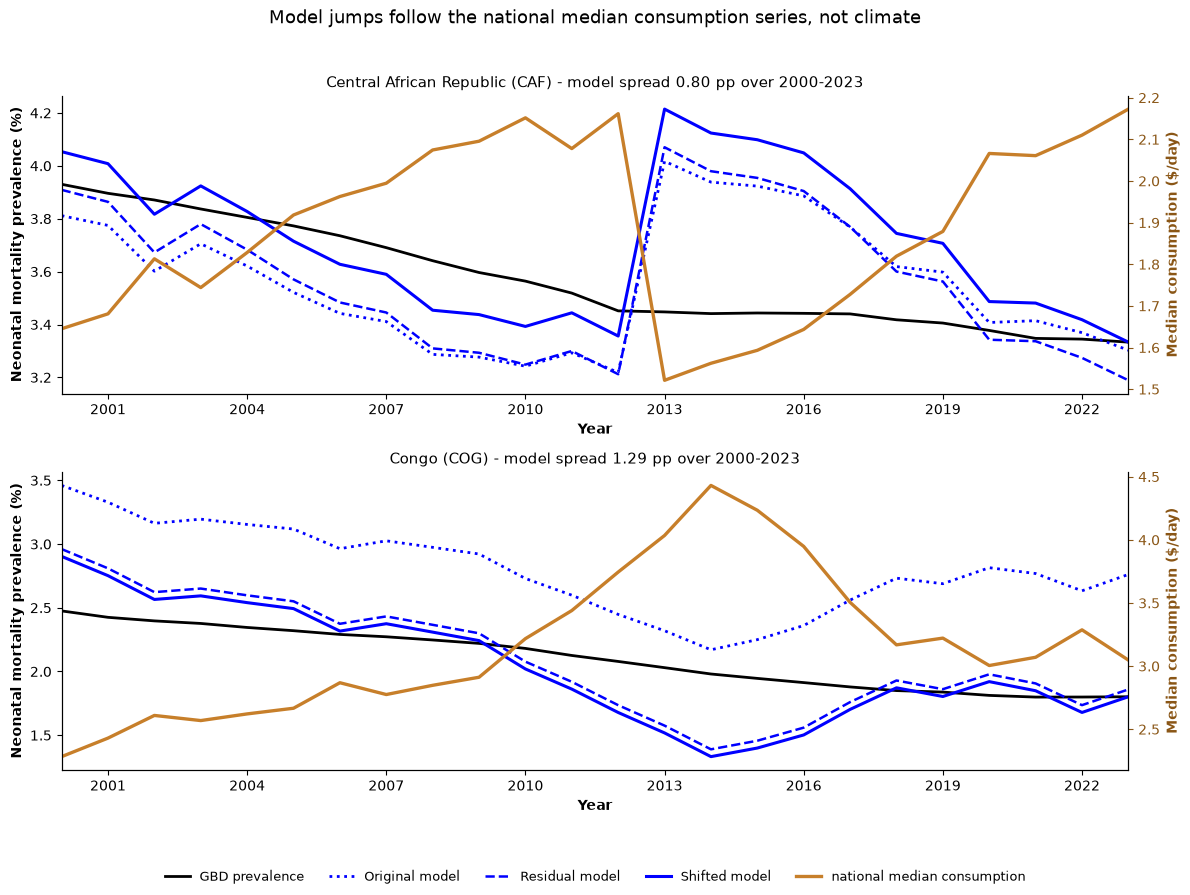


Central African Republic: income $1.52-$2.17/day, largest 1-yr move 29.6%; model 3.219-4.017%

Congo: income $2.28-$4.43/day, largest 1-yr move 11.2%; model 2.170-3.460%


In [ ]:
# Central African Republic and Congo: model jumps against the income series ##
# Both countries' prediction lines step around in the published pdf. This puts
# the driver on the same axes: the national median consumption the model reads
# as consumption_median_RT, on the right-hand y axis.
#
# Runs after the subset cell, reusing sub_agg (the population-weighted
# hierarchy aggregate) and sub_hier.
SHK_ISOS = ["CAF", "COG"]
SHK_LDI = f"{SUB_ROOT}/input/ldi/v8/national_estimates.parquet"
SHK_YEARS = (2000, 2023)
SHK_LINES = [
    ("gbd_value", "black", "-", 2.0, "GBD prevalence"),
    ("model_value", "blue", ":", 2.0, "Original model"),
    ("residual_model_value", "blue", "--", 1.8, "Residual model"),
    ("adjusted_model_value", "blue", "-", 2.2, "Shifted model"),
]

shk_ids = {
    iso: int(sub_hier.loc[sub_hier["ihme_loc_id"] == iso, "location_id"].iloc[0])
    for iso in SHK_ISOS
}
shk_names = {
    iso: sub_hier.loc[sub_hier.location_id == lid, "location_name"].iloc[0]
    for iso, lid in shk_ids.items()
}

# national median consumption, per day, exactly as inference reads it
shk_inc = pd.read_parquet(
    SHK_LDI,
    columns=["ihme_loc_id", "year_id", "scenario", "population_percentile", "ldipc"],
    filters=[("population_percentile", "==", 0.5), ("scenario", "==", "reference")],
)
shk_inc = shk_inc[shk_inc.ihme_loc_id.isin(SHK_ISOS)].copy()
shk_inc["median_pd"] = shk_inc["ldipc"] / 365.0

# sex-averaged prevalence, weighted by the population already carried on sub_agg
_v = [c for c, *_ in SHK_LINES if c in sub_agg.columns]
_s = sub_agg[sub_agg.location_id.isin(shk_ids.values())].copy()
for _c in _v:
    _s[_c] = _s[_c] * _s["population"]
shk = _s.groupby(["location_id", "year_id"], as_index=False)[_v + ["population"]].sum()
for _c in _v:
    shk[_c] = shk[_c] / shk["population"]

fig, axes = plt.subplots(len(SHK_ISOS), 1, figsize=(12, 9), squeeze=False)
shk_handles, shk_labels = [], []
for ax, iso in zip(axes.ravel(), SHK_ISOS):
    lid = shk_ids[iso]
    blk = shk[shk.location_id == lid].sort_values("year_id")
    blk = blk[(blk.year_id >= SHK_YEARS[0]) & (blk.year_id <= SHK_YEARS[1])]
    inc = (
        shk_inc[shk_inc.ihme_loc_id == iso]
        .sort_values("year_id")
        .set_index("year_id")["median_pd"]
    )
    inc = inc.loc[SHK_YEARS[0] : SHK_YEARS[1]]

    for col, colour, ls, lw, lab in SHK_LINES:
        if col in blk.columns:
            ax.plot(blk.year_id, 100 * blk[col], color=colour, ls=ls, lw=lw, label=lab)

    ax2 = ax.twinx()
    ax2.plot(
        inc.index,
        inc.values,
        color="#c77f2a",
        lw=2.4,
        zorder=2,
        label="national median consumption",
    )
    ax2.set_ylabel("Median consumption ($/day)", fontweight="bold", color="#8a5616")
    ax2.tick_params(axis="y", colors="#8a5616")
    ax2.spines["top"].set_visible(False)

    ax.set_xlim(*SHK_YEARS)
    ax.xaxis.set_major_locator(MaxNLocator(8, integer=True))
    ax.set_ylabel("Neonatal mortality prevalence (%)", fontweight="bold")
    ax.set_xlabel("Year", fontweight="bold")
    ax.set_title(
        f"{shk_names[iso]} ({iso}) - model spread "
        f"{100 * (blk[_v[1]].max() - blk[_v[1]].min()):.2f} pp over "
        f"{SHK_YEARS[0]}-{SHK_YEARS[1]}",
        fontsize=11,
    )
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    if not shk_handles:
        _h1, _l1 = ax.get_legend_handles_labels()
        _h2, _l2 = ax2.get_legend_handles_labels()
        shk_handles, shk_labels = _h1 + _h2, _l1 + _l2

fig.legend(
    shk_handles, shk_labels, loc="lower center", ncol=5, fontsize=9, frameon=False
)
fig.suptitle(
    "Model jumps follow the national median consumption series, not climate",
    fontsize=13,
)
fig.tight_layout(rect=(0, 0.07, 1, 0.96))
plot_path = f"{PLOT_OUTPUT}caf_congo_income_shocks.pdf"
fig.savefig(plot_path, bbox_inches="tight")
print(f"Saved {plot_path}")
plt.show()

for iso in SHK_ISOS:
    inc = (
        shk_inc[shk_inc.ihme_loc_id == iso]
        .sort_values("year_id")
        .set_index("year_id")["median_pd"]
        .loc[SHK_YEARS[0] : SHK_YEARS[1]]
    )
    blk = (
        shk[shk.location_id == shk_ids[iso]]
        .set_index("year_id")
        .loc[SHK_YEARS[0] : SHK_YEARS[1]]
    )
    print(
        f"\n{shk_names[iso]}: income ${inc.min():.2f}-${inc.max():.2f}/day, "
        f"largest 1-yr move {100 * inc.pct_change().abs().max():.1f}%; "
        f"model {100 * blk.model_value.min():.3f}-"
        f"{100 * blk.model_value.max():.3f}%"
    )